# Agent

- 将所有 Agent 的创建方式统一为一个入口：create_agent()

In [ ]:
from unittest import result

from charset_normalizer.cd import coherence_ratio
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek")
agent=create_agent(
    model=model,
    tools=[tool1,tool2],
    system_prompt="Agent的行为命令"
)

result=agent.invoke({
    "messages":[{"role":"user","content":"问题"}]
})

## create_agent完整参数
```
    from langchain.agents import create_agent

    agent = create_agent(
        model: str | BaseChatModel, # 必需：聊天模型
        tools: List[BaseTool], # 必需：工具列表
        *,
        system_prompt: str = "", # 系统提示词
        middleware: Seguence[AgentMiddleware[StateT_co, ContextT]] = () # 中间件
        interrupt_before: List[str] = None, # 在某些工具前暂停（人机协作）
        interrupt_after: List[str] = None, # 在某些工具后暂停
        debug: bool = False # 调试模式
        name: str 丨 None = None, # 设置模型名称
    )
```

### 传入模型

agent底层实现是一个图结构

<class 'langgraph.graph.state.CompiledStateGraph'>


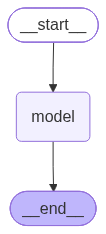

In [1]:
# Agent根据传入的模型字符串，自主创建对象

from langchain.agents import  create_agent
from dotenv import load_dotenv

load_dotenv(override=True)

agent=create_agent("deepseek-flash")
print(type(agent))

from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

<class 'langgraph.graph.state.CompiledStateGraph'>


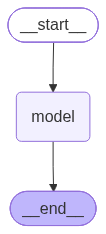

In [2]:
# 传入模型对象
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
import os

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek"
)
agent = create_agent(model)
print(type(agent))
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

## 调用agent

### agent.invoke() 是最基本的同步调用方式。会阻塞程序执行直到看到最终结果

In [6]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
from rich import  print as rprint

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek"
)

agent=create_agent(model)
response=agent.invoke({"messages":["你好"]}) #默认是HumanMessage
print(type(response))
rprint(response)
print(response["messages"][-1].content)

<class 'dict'>


{
    'messages': [
        HumanMessage(
            content='你好',
            additional_kwargs={},
            response_metadata={},
            id='f043a09f-855e-479e-8e69-25be6ee5e492'
        ),
        AIMessage(
            content='你好！很高兴见到你 
😊\n\n有什么我可以帮忙的吗？无论是聊天、解答问题、写作、学习还是其他方面，我都很乐意帮你。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user just said "你好" (Hello) in Chinese. I should respond warmly in 
Chinese and offer help.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 55,
                    'prompt_tokens': 31,
                    'total_tokens': 86,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 23,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 31
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '2f9c7a0a-06a5-4200-b7db-76a371ea45a3',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1cfea-b8ac-775a-9218-f8cd610e8c15-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 31,
                'output_tokens': 55,
                'total_tokens': 86,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 23}
            }
        )
    ]
}

你好！很高兴见到你 😊

有什么我可以帮忙的吗？无论是聊天、解答问题、写作、学习还是其他方面，我都很乐意帮你。


In [8]:
#在messages列表开头加入system角色定义Agent行为

from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
from rich import  print as rprint

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek"
)

agent=create_agent(model)
resp=agent.invoke({"messages":[
    {"role":"system","content":"你是一名耐心的老师"},
    {"role":"user","content":"1+2+n？"}
]})
rprint(resp)

{
    'messages': [
        SystemMessage(
            content='你是一名耐心的老师',
            additional_kwargs={},
            response_metadata={},
            id='1da983de-0b8f-4d63-84af-8e66181643de'
        ),
        HumanMessage(
            content='1+2+n？',
            additional_kwargs={},
            response_metadata={},
            id='bbabb45a-76d8-41bf-bb52-4f7aadfb8e8d'
        ),
        AIMessage(
            content='如果 \\(n\\) 是一个数（变量），那么：\n\n\\[\n1+2+n=3+n=n+3\n\\]\n\n如果你告诉我 \\(n\\) 
等于几，我就可以帮你算出具体结果。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': '我们需要回答用户中文“1+2+n？”这看起来是一个数学表达式问题。可能用户想问 1+2+n
等于多少？需要澄清 n 是变量，所以等于 n+3。也可能是在问“1+2+n？”简单。需要以老师耐心语气。回答：如果 n 
是变量，1+2+n = 3+n = n+3。若 n 有具体数值代入。可能需要解释。注意用户用“？”可能期待。最终简洁。'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 145,
                    'prompt_tokens': 39,
                    'total_tokens': 184,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 102,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 39
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '08645858-8558-4a1b-8959-822198bf4084',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1cfed-58fc-736d-8f31-33def52b5d38-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 39,
                'output_tokens': 145,
                'total_tokens': 184,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 102}
            }
        )
    ]
}

# 绑定工具

langchain内置工具
![image.png](images/tools.png)

In [11]:
from langchain.agents import  create_agent
from langchain.tools import  tool
from rich import print as rprint

@tool(parse_docstring=True)
def get_weather(city:str)->str:
    """
    天气查询工具

    Args:
        city:城市名称
    """

    return f"{city}的天气为晴朗，25度"

agent=create_agent(model=model,
                   tools=[get_weather])

response=agent.invoke({"messages":[
    {"role":"system","content":"你是一个天气查询助手，只回答天气相关的问题，其他的回复不知道"},
   # {"role":"user","content":"1+1=？"}
    {"role":"user","content":"北京的天气如何呢"}
]})

rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个天气查询助手，只回答天气相关的问题，其他的回复不知道',
            additional_kwargs={},
            response_metadata={},
            id='55d8c752-c4dd-4ef3-875f-48caab2e780b'
        ),
        HumanMessage(
            content='北京的天气如何呢',
            additional_kwargs={},
            response_metadata={},
            id='9e41eedd-4757-4589-b853-70b652684895'
        ),
        AIMessage(
            content='',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': "The user asks about Beijing's weather. I should call the weather tool."
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 54,
                    'prompt_tokens': 313,
                    'total_tokens': 367,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 15,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 128},
                    'prompt_cache_hit_tokens': 128,
                    'prompt_cache_miss_tokens': 185
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '27ed074c-da4e-415a-a737-ddda781a58a3',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1cff6-2e00-743b-a2f4-d17bbd7ddaf8-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_00_rM5bV41GZRPGG5NyViEJ0873',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 313,
                'output_tokens': 54,
                'total_tokens': 367,
                'input_token_details': {'cache_read': 128},
                'output_token_details': {'reasoning': 15}
            }
        ),
        ToolMessage(
            content='北京的天气为晴朗，25度',
            name='get_weather',
            id='1f51e3e3-82fd-4237-bfac-d770825ab1d0',
            tool_call_id='call_00_rM5bV41GZRPGG5NyViEJ0873'
        ),
        AIMessage(
            content='北京今天是晴天，气温25度，天气不错呢～出门记得做好防晒哦。',
            additional_kwargs={'refusal': None, 'reasoning_content': ''},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 19,
                    'prompt_tokens': 386,
                    'total_tokens': 405,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 128},
                    'prompt_cache_hit_tokens': 128,
                    'prompt_cache_miss_tokens': 258
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '17335071-80a2-40f5-a787-19f1e294350f',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1cff6-34a6-71ff-844c-3f8d538fe9f9-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 386,
                'output_tokens': 19,
                'total_tokens': 405,
                'input_token_details': {'c

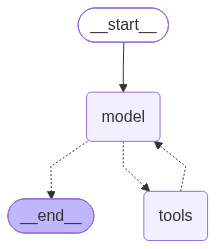

In [12]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [13]:
from langchain_tavily import  TavilySearch
from dotenv import load_dotenv
import os
load_dotenv(override=True)

web_search=TavilySearch(
    tavily_api_key=os.getenv("TAILLY_API_KEY"),
    max_results=2
)

web_search.invoke("请问南京邮电大学2026年毕业生有多少人去了bat")

{'query': '请问南京邮电大学2026年毕业生有多少人去了bat',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.163.com/dy/article/L9UAM5FN055683JA.html',
   'title': '南京邮电大学就业率是多少？这份数据比传言更有说服力|南京邮电大学|本科生|毕业生|民办本科_手机网易网',
   'content': '# 南京邮电大学就业率是多少？这份数据比传言更有说服力\n\n志愿研究院\n\n关于南京邮电大学的就业，坊间说法很多，但最可信的还是学校自己公布的数。近年来本科毕业生去向落实率稳定在95%以上；2025届毕业生中本科深造率超过53%，意味着每两名本科生就有一名继续读研或出国；保研率方面，2025届达到11.32%，2026届推免人数预计增至775人，保研率有望突破13%，呈逐年上升的态势。就业率稳、深造率高、薪资后劲足，这三个特征叠在一起，才是这所学校真正的竞争力。\n\n一、就业基本盘：落实率稳，王牌专业近乎全员就业\n\n先看基本面。2025届学校毕业生共8444人，其中本科生5589人、硕士研究生2774人、博士研究生81人。通信工程、电子信息等王牌专业的去向落实率接近满分，几乎实现毕业即就业。从单位规模看，毕业生就业主要集中在1001人及以上规模的用人单位，大型企业占比很高——这一点很关键，因为它决定了职业起点的高度和后续发展的稳定性。\n\n二、行业对口度，才是高就业率的真正底气 [...] 高就业率不是偶然，而是行业对口度高的必然结果。就业量最大的行业是信息传输、软件和信息技术服务业，本科生占比接近45%；细分行业中，计算机通信和其他电子设备制造业占20%、软件和信息技术服务业占17%、电信广播电视和卫星传输服务占15%、互联网和相关服务占8%。换句话说，毕业生的去向高度集中在国家战略急需的新一代信息技术领域，而这些领域的人才需求仍在扩张。学校还总结出三个特点：去向集中在大企业、信息底色足、留苏比例高。\n\n三、产教融合：把课堂搬进产业园区\n\n就业质量高的背后，是极具前瞻性的育人体系。学校推行驻入园区、嵌入产业、融入企业的产教融合新模式，

In [14]:
from langchain.agents import  create_agent
from langchain.tools import  tool
from langchain_tavily import TavilySearch
from rich import print as rprint

web_search=TavilySearch(max_results=2)

agent=create_agent(model=model,
                   tools=[web_search])

response=agent.invoke({"messages":[
    {"role":"system","content":"你是一个万能的查询助手，可以查询到所有问题"},
   # {"role":"user","content":"1+1=？"}
    {"role":"user","content":"请问南京邮电大学2026年毕业生有多少人去了bat"}
]})

rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个万能的查询助手，可以查询到所有问题',
            additional_kwargs={},
            response_metadata={},
            id='9d957a55-293e-4f05-9a97-70a4943cbdba'
        ),
        HumanMessage(
            content='请问南京邮电大学2026年毕业生有多少人去了bat',
            additional_kwargs={},
            response_metadata={},
            id='119f434f-e246-4495-a02f-6853de606daf'
        ),
        AIMessage(
            content='我来帮你查询相关信息。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user asks: "How many graduates of Nanjing University of Posts and 
Telecommunications (南京邮电大学) in 2026 went to BAT (Baidu, Alibaba, Tencent)?" \n\n2026 graduates - it\'s 2025 
now presumably, so 2026 graduates\' employment data wouldn\'t be complete yet. Let me search.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 214,
                    'prompt_tokens': 1850,
                    'total_tokens': 2064,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 70,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 1850
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '92201932-bb3d-448a-a77b-cfa2e0999fa6',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1cffc-c5a8-7131-afb4-8ad690ac8e77-0',
            tool_calls=[
                {
                    'name': 'tavily_search',
                    'args': {
                        'query': '南京邮电大学 2026届毕业生 就业质量报告 BAT 百度 阿里 腾讯',
                        'search_depth': 'advanced'
                    },
                    'id': 'call_00_gwUTZ1DVMxbOVl9VsveI7988',
                    'type': 'tool_call'
                },
                {
                    'name': 'tavily_search',
                    'args': {
                        'query': '南京邮电大学 毕业生 就业质量报告 华为 腾讯 阿里 百度 人数',
                        'search_depth': 'advanced'
                    },
                    'id': 'call_01_20cOQGFaKiLcQ68yUQgA4115',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 1850,
                'output_tokens': 214,
                'total_tokens': 2064,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 70}
            }
        ),
        ToolMessage(
            content='{"query": "南京邮电大学 2026届毕业生 就业质量报告 BAT 百度 阿里 腾讯", "follow_up_questions": 
null, "answer": null, "images": [], "results": [{"url": "https://www.eefocus.com/article/1854585.html", "title": 
"南邮2024年就业报告，华为202人！ - 与非网", "content": 
"电子硬件助手\\n元器件查询\\n\\n热搜\\n\\n搜索历史清空\\n\\n加入星计划，您可以享受以下权益：\\n\\n产业图谱\\n\\n# 
南邮2024年就业报告，华为202人！\\n\\n南京邮电大学于 2025 年 6 月 20 日在其公众号公布了 2024 
届毕业生就业报告。报告显示，2024 届毕业生总数达 8048 人，其中本科生有 5358 人，研究生为 2690 
人。\\n\\n从就业方向来看，南邮毕业生的去向主要集中在通信、信息科技、互联网、金融等领域。通信行业作为南邮毕业生的传
统就业高地，通信运营商成为吸纳人才的主力军。中国电信、中国移动、中国联通三家大型电信运营商共吸纳 789 
名南邮毕业生，其中中国电信录用 406 人，中国移动录用 284 人，中国联通录用 99 人。通信设备企业同样是招聘大户，华为以 
202 人的录用数量遥遥领先，中兴、小米分别录用 77 人、55 人，这些企业为毕业生提供了参与 5G 
技术研发、通信设备制造等前沿领域工作的机会 
。\\n\\n在互联网领域，阿里巴巴、腾讯、百度等知名大厂也向南邮毕业生抛出橄榄枝，为其提供互联网技术研发、产品设计、运
营管理等关键岗位，助力毕业生在数字经济浪潮中施展才华。除企业外，不少毕业生选择进入政府机构，参与通信政策制定、技术
标准规范、行业监管等工作；或是投身科研院所，协助完成国家重点研究项目，推动学科前沿研究成果转化。中国邮政、中国电科
等央企和国企，也凭借稳定的工作环境，吸引了众多南邮学子加入。 [...] 在就业质量上，南邮表现出色。2023 
届本科毕业生的年终就

In [15]:
print(response["messages"][-1].content)

## 直接结论

**目前查不到“南邮2026届毕业生有多少人去了BAT”的官方数据，因为2026届毕业生还没毕业，就业质量报告尚未发布。**

### 一、为什么没有这个数据

- 南京邮电大学2026届毕业生正常于 **2026年6月毕业**。学校的《毕业生就业质量年度报告》一般在毕业当年年底至次年（即2026年末—2027年中）才公布，其中才会统计“主要就业单位录用人数”。
- 所以现在（2026届秋招/春招进行中）任何“2026届去BAT多少人”的具体数字都只能是传闻，没有官方统计口径。

### 二、能查到的2026届相关信息：只有生源规模

南邮就业信息网公布的2026届生源信息：
- 毕业生总数 **约9075人**（另有通知口径为9184人，两个版本略有差异）
- 其中本科毕业生 **6149人**、硕士 **2827人**、博士 **99人**

（来源：南京邮电大学就业信息网 njupt.91job.org.cn）

### 三、可参考的最近官方数据：2024届

南邮2024届就业质量报告（2025年6月20日发布，共8048人：本科5358人、研究生2690人）中公布的主要录用人数：

| 单位 | 录用人数 |
|---|---|
| 中国电信 | 406人 |
| 中国移动 | 284人 |
| 华为 | 202人 |
| 中国联通 | 99人 |
| 中兴 | 77人 |
| 小米 | 55人 |

关于BAT：报告只笼统表述“阿里巴巴、腾讯、百度等知名互联网大厂也向南邮毕业生抛出橄榄枝”，**并未单独公布百度、阿里、腾讯各自的具体录用人数**。南邮历年报告的主要就业单位统计表一般只列到录用规模较大的几十家单位，BAT中单家录用人数通常较小（多在个位数到二三十人量级），往往不进入单独列示的榜单。

### 四、旁证参考（注意别混淆）

北京邮电大学2025届公布：“822人入职阿里巴巴、腾讯、美团、字节跳动、百度等互联网头部企业”，即“互联网头部企业合计822人”。北邮规模与互联网行业偏好都明显强于南邮；不要把这一数字当成南邮的数据，也不要当成BAT一家的数字。

### 五、想拿到准确答案的建议

1. **2026年底—2027年中**，关注“南京邮电大学就业信息网（njupt.91job.org.cn）”以及“南邮就业”微信公众号

In [19]:
from langchain.agents import create_agent
from langchain.tools import tool
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

@tool(parse_docstring=True)
def get_school(school:str)->str:
    """

    学校查询工具

    Args:
         school:学校名称
    """

    return f"{school}，这个学校不错"


@tool(parse_docstring=True)
def get_weather(city:str)->str:
    """

    天气查询工具

    Args:
        city:str
    """

    return f"{city}这里天气不错"

agent=create_agent(model=model,
                   tools=[get_school,get_weather])

response=agent.invoke({
    "messages":["你好，今天南京的天气怎么样，南邮这个学校怎么样"]
})

rprint(response)

{
    'messages': [
        HumanMessage(
            content='你好，今天南京的天气怎么样，南邮这个学校怎么样',
            additional_kwargs={},
            response_metadata={},
            id='1b2630f2-1fa4-4342-be0f-32d37dd43035'
        ),
        AIMessage(
            content='我来帮你查一下南京的天气和南邮的情况。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user asks about Nanjing weather and about NJUPT (南京邮电大学). I can 
call both tools in parallel.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 105,
                    'prompt_tokens': 357,
                    'total_tokens': 462,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 24,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 357
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '8824e3e0-ece4-4550-8411-0b490e8d2e19',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d007-b7e4-7557-a581-da20623b77f5-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '南京'},
                    'id': 'call_00_wHV3Y47cQYxTNAjVimM53832',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_school',
                    'args': {'school': '南京邮电大学'},
                    'id': 'call_01_taEp5JC9gffRC5LkGMqS0760',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 357,
                'output_tokens': 105,
                'total_tokens': 462,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 24}
            }
        ),
        ToolMessage(
            content='南京这里天气不错',
            name='get_weather',
            id='6495c262-c9fc-463e-8598-30e80435fc6a',
            tool_call_id='call_00_wHV3Y47cQYxTNAjVimM53832'
        ),
        ToolMessage(
            content='南京邮电大学，这个学校不错',
            name='get_school',
            id='ef15a464-a36e-4749-bf5c-b582b89903c3',
            tool_call_id='call_01_taEp5JC9gffRC5LkGMqS0760'
        ),
        AIMessage(
            content='我查到的信息如下：\n\n**南京天气**：查询结果显示「南京这里天气不错」。不过这个回答比较笼统，没
有给出具体温度、是否下雨等细节，建议你出门前再看看手机上的实时天气预报，确认一下气温和降水情况。\n\n**南京邮电大学*
*：查询结果显示「这个学校不错」。同样地，这个回答也比较简略，没有给出具体的学科特色、排名等信息。\n\n如果按我了解到
的情况补充一些参考（非实时数据，具体以官方信息为准）：\n\n- 
南邮是位于南京的公办高校，以**信息与通信工程、电子科学与技术、计算机**等方向见长，属于行业特色鲜明的学校。\n- 
在通信、电子信息领域就业口碑比较好，运营商、通信设备厂商、互联网企业都是常见去向。\n- 不是 
985/211，但在信息类行业内认可度较高，录取分数在江苏省属高校里偏高。\n\n如果你想了解更具体的内容（比如某个专业的实力
、近年录取分数、宿舍条件等），可以告诉我，我再帮你细看；如果是要填报志愿，建议查一下官方招生网和最新学科评估结果。'
,
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The tool outputs are quite vague. I should report honestly what I got and 
note the limited detail.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 251,
                    'prompt_tokens': 493,
                    'total_tokens': 744,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 20,
                        'rejected_prediction_tokens': None
                   

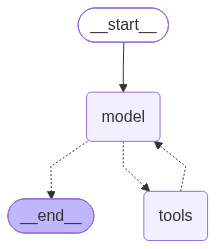

In [20]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

## 工具重试机制

In [21]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from rich import print as rprint
load_dotenv(override=True)
flag = 0

@tool(parse_docstring=True)
def get_weather(city:str)->str:
    """
    天气查询工具

    Args:
        city:城市
    """
    global flag
    flag+=1

    if flag < 3:
        # raise Exception("暂时无法访问")
        return "TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试"

    return f"{city}天气不错"

messages = [
    SystemMessage("""
    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    """),
    HumanMessage("你好，杭州今天的天气如何？")
]
agent = create_agent(model, tools=[get_weather])
response = agent.invoke({"messages": messages})

for msg in response["messages"]:
    msg.pretty_print()

================================ System Message ================================


    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    
================================ Human Message =================================

你好，杭州今天的天气如何？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_wxoZXLl6nlQ1SGy9wZkR3139)
 Call ID: call_00_wxoZXLl6nlQ1SGy9wZkR3139
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_V2xsFeLc8bTzWhIH1D4z9175)
 Call ID: call_00_V2xsFeLc8bTzWhIH1D4z9175
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
=======

## agent调用工具原则

 - 依据工具的docstring

AI根据：
1.问题内容
2.每个工具描述
3.自动选择匹配的工具

## agent选错工具

- 原因：多个工具功能相似，工具太多导致混淆


解决：
1.只给必要的工具
2.工具当中明确区分
3.在system_prompt中说明工具场景